In [1]:
from IPython.core.display import HTML

HTML("""
<style>

h1 { color: blue !important; }
h2 { color: green !important; }
</style>
""")

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix,accuracy_score,roc_curve,classification_report
import seaborn as sns
import matplotlib.pyplot as plt 
from keras import optimizers,losses,metrics # open anaconda promt - pip install keras
from keras.models import Sequential
from keras.layers import Dense
from sklearn.metrics import precision_recall_curve

# Step 1: Read and explore the data

In [2]:
data =  pd.read_csv("Hotel Reservations.csv")

In [3]:
data.head(100)

,Booking_ID,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,INN00001,2,0,1,2,Meal Plan 1,0,Room_Type 1,224,2017,10,2,Offline,0,0,0,65.00,0,Not_Canceled
1,INN00002,2,0,2,3,Not Selected,0,Room_Type 1,5,2018,11,6,Online,0,0,0,106.68,1,Not_Canceled
2,INN00003,1,0,2,1,Meal Plan 1,0,Room_Type 1,1,2018,2,28,Online,0,0,0,60.00,0,Canceled
3,INN00004,2,0,0,2,Meal Plan 1,0,Room_Type 1,211,2018,5,20,Online,0,0,0,100.00,0,Canceled
4,INN00005,2,0,1,1,Not Selected,0,Room_Type 1,48,2018,4,11,Online,0,0,0,94.50,0,Canceled
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,INN00096,2,1,0,2,Meal Plan 1,1,Room_Type 1,134,2018,8,4,Online,0,0,0,130.50,2,Not_Canceled
96,INN00097,2,0,0,2,Meal Plan 2,0,Room_Type 1,320,2018,8,18,Online,0,0,0,115.00,1,Canceled
97,INN00098,2,0,0,4,Meal Plan 1,0,Room_Type 1,118,2018,4,13,Online,0,0,0,90.95,1,Not_Canceled
98,INN00099,2,0,0,3,Meal Plan 1,0,Room_Type 1,30,2018,11,17,Online,0,0,0,76.08,1,Not_Canceled


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36275 entries, 0 to 36274
Data columns (total 19 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Booking_ID                            36275 non-null  object 
 1   no_of_adults                          36275 non-null  int64  
 2   no_of_children                        36275 non-null  int64  
 3   no_of_weekend_nights                  36275 non-null  int64  
 4   no_of_week_nights                     36275 non-null  int64  
 5   type_of_meal_plan                     36275 non-null  object 
 6   required_car_parking_space            36275 non-null  int64  
 7   room_type_reserved                    36275 non-null  object 
 8   lead_time                             36275 non-null  int64  
 9   arrival_year                          36275 non-null  int64  
 10  arrival_month                         36275 non-null  int64  
 11  arrival_date   

In [5]:
data.describe()

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,required_car_parking_space,lead_time,arrival_year,arrival_month,arrival_date,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests
count,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000,36275.000000
mean,1.844962,0.105279,0.810724,2.204300,0.030986,85.232557,2017.820427,7.423653,15.596995,0.025637,0.023349,0.153411,103.423539,0.619655
std,0.518715,0.402648,0.870644,1.410905,0.173281,85.930817,0.383836,3.069894,8.740447,0.158053,0.368331,1.754171,35.089424,0.786236
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2017.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,0.000000,0.000000,1.000000,0.000000,17.000000,2018.000000,5.000000,8.000000,0.000000,0.000000,0.000000,80.300000,0.000000
50%,2.000000,0.000000,1.000000,2.000000,0.000000,57.000000,2018.000000,8.000000,16.000000,0.000000,0.000000,0.000000,99.450000,0.000000
75%,2.000000,0.000000,2.000000,3.000000,0.000000,126.000000,2018.000000,10.000000,23.000000,0.000000,0.000000,0.000000,120.000000,1.000000
max,4.000000,10.000000,7.000000,17.000000,1.000000,443.000000,2018.000000,12.000000,31.000000,1.000000,13.000000,58.000000,540.000000,5.000000


In [6]:
print(data['type_of_meal_plan'].value_counts())

Meal Plan 1     27835
Not Selected     5130
Meal Plan 2      3305
Meal Plan 3         5
Name: type_of_meal_plan, dtype: int64


In [7]:
print(data['room_type_reserved'].value_counts())

Room_Type 1    28130
Room_Type 4     6057
Room_Type 6      966
Room_Type 2      692
Room_Type 5      265
Room_Type 7      158
Room_Type 3        7
Name: room_type_reserved, dtype: int64


In [8]:
print(data['market_segment_type'].value_counts())

Online           23214
Offline          10528
Corporate         2017
Complementary      391
Aviation           125
Name: market_segment_type, dtype: int64


In [9]:
print(data['booking_status'].value_counts())

Not_Canceled    24390
Canceled        11885
Name: booking_status, dtype: int64


In [10]:
print(data['required_car_parking_space'].value_counts())

0    35151
1     1124
Name: required_car_parking_space, dtype: int64


In [11]:
print(data['repeated_guest'].value_counts())

0    35345
1      930
Name: repeated_guest, dtype: int64


In [12]:
print(data['arrival_year'].value_counts())

2018    29761
2017     6514
Name: arrival_year, dtype: int64


In [13]:
print(data['arrival_month'].value_counts())

10    5317
9     4611
8     3813
6     3203
12    3021
11    2980
7     2920
4     2736
5     2598
3     2358
2     1704
1     1014
Name: arrival_month, dtype: int64


In [14]:
print(data['no_of_previous_bookings_not_canceled'].value_counts().head(10))
# As there are only ~3% repeat customers using previous booking data is not significant

0     35463
1       228
2       112
3        80
4        65
5        60
6        36
7        24
8        23
10       19
Name: no_of_previous_bookings_not_canceled, dtype: int64


In [15]:
print(data['no_of_special_requests'].value_counts().head(10))


0    19777
1    11373
2     4364
3      675
4       78
5        8
Name: no_of_special_requests, dtype: int64


In [16]:
print(data['no_of_adults'].value_counts())

2    26108
1     7695
3     2317
0      139
4       16
Name: no_of_adults, dtype: int64


In [17]:
print(data['no_of_children'].value_counts())
#Number of children 9 and 10 looks like outlier

0     33577
1      1618
2      1058
3        19
9         2
10        1
Name: no_of_children, dtype: int64


In [18]:
#oulier removal
data = data[data['no_of_children']<=3]
data.reset_index(inplace=True)

In [19]:
print(data.columns)

Index(['index', 'Booking_ID', 'no_of_adults', 'no_of_children',
       'no_of_weekend_nights', 'no_of_week_nights', 'type_of_meal_plan',
       'required_car_parking_space', 'room_type_reserved', 'lead_time',
       'arrival_year', 'arrival_month', 'arrival_date', 'market_segment_type',
       'repeated_guest', 'no_of_previous_cancellations',
       'no_of_previous_bookings_not_canceled', 'avg_price_per_room',
       'no_of_special_requests', 'booking_status'],
      dtype='object')


# Step 2: Create features

In [20]:
numerical_features = ['no_of_adults', 'no_of_children', 'no_of_weekend_nights',
       'no_of_week_nights', 'required_car_parking_space', 'lead_time','repeated_guest',
       'avg_price_per_room', 'no_of_previous_bookings_not_canceled','no_of_special_requests']

In [21]:
categorical_features  = ['type_of_meal_plan','room_type_reserved','market_segment_type','arrival_month']


In [22]:
data = data[numerical_features + categorical_features + ['booking_status']  ]
data.head(10)

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,required_car_parking_space,lead_time,repeated_guest,avg_price_per_room,no_of_previous_bookings_not_canceled,no_of_special_requests,type_of_meal_plan,room_type_reserved,market_segment_type,arrival_month,booking_status
0,2,0,1,2,0,224,0,65.00,0,0,Meal Plan 1,Room_Type 1,Offline,10,Not_Canceled
1,2,0,2,3,0,5,0,106.68,0,1,Not Selected,Room_Type 1,Online,11,Not_Canceled
2,1,0,2,1,0,1,0,60.00,0,0,Meal Plan 1,Room_Type 1,Online,2,Canceled
3,2,0,0,2,0,211,0,100.00,0,0,Meal Plan 1,Room_Type 1,Online,5,Canceled
4,2,0,1,1,0,48,0,94.50,0,0,Not Selected,Room_Type 1,Online,4,Canceled
5,2,0,0,2,0,346,0,115.00,0,1,Meal Plan 2,Room_Type 1,Online,9,Canceled
6,2,0,1,3,0,34,0,107.55,0,1,Meal Plan 1,Room_Type 1,Online,10,Not_Canceled
7,2,0,1,3,0,83,0,105.61,0,1,Meal Plan 1,Room_Type 4,Online,12,Not_Canceled
8,3,0,0,4,0,121,0,96.90,0,1,Meal Plan 1,Room_Type 1,Offline,7,Not_Canceled
9,2,0,0,5,0,44,0,133.44,0,3,Meal Plan 1,Room_Type 4,Online,10,Not_Canceled


In [23]:
data = pd.get_dummies(data, columns =categorical_features, drop_first= False)
data['booking_status'] = data['booking_status'].map({'Not_Canceled':0, 'Canceled' : 1})

# Step 3: Train test split the data

In [24]:
def train_test_split_and_features(data):
    y = data['booking_status']
    x = data.drop('booking_status',axis=1)
    x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, shuffle = False, random_state = 0)
    features = list(x.columns)
    return x_train, x_test, y_train, y_test,features


In [25]:
x_train, x_test, y_train, y_test,features = train_test_split_and_features(data)

In [26]:
x_train.head(10)

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,required_car_parking_space,lead_time,repeated_guest,avg_price_per_room,no_of_previous_bookings_not_canceled,no_of_special_requests,...,arrival_month_3,arrival_month_4,arrival_month_5,arrival_month_6,arrival_month_7,arrival_month_8,arrival_month_9,arrival_month_10,arrival_month_11,arrival_month_12
0,2,0,1,2,0,224,0,65.00,0,0,...,0,0,0,0,0,0,0,1,0,0
1,2,0,2,3,0,5,0,106.68,0,1,...,0,0,0,0,0,0,0,0,1,0
2,1,0,2,1,0,1,0,60.00,0,0,...,0,0,0,0,0,0,0,0,0,0
3,2,0,0,2,0,211,0,100.00,0,0,...,0,0,1,0,0,0,0,0,0,0
4,2,0,1,1,0,48,0,94.50,0,0,...,0,1,0,0,0,0,0,0,0,0
5,2,0,0,2,0,346,0,115.00,0,1,...,0,0,0,0,0,0,1,0,0,0
6,2,0,1,3,0,34,0,107.55,0,1,...,0,0,0,0,0,0,0,1,0,0
7,2,0,1,3,0,83,0,105.61,0,1,...,0,0,0,0,0,0,0,0,0,1
8,3,0,0,4,0,121,0,96.90,0,1,...,0,0,0,0,1,0,0,0,0,0
9,2,0,0,5,0,44,0,133.44,0,3,...,0,0,0,0,0,0,0,1,0,0


# Step 4: Scale the data for NN

In [27]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

x_train[numerical_features] = scaler.fit_transform(x_train[numerical_features])
x_test[numerical_features] = scaler.transform(x_test[numerical_features])

In [28]:
x_train.head(10)

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,required_car_parking_space,lead_time,repeated_guest,avg_price_per_room,no_of_previous_bookings_not_canceled,no_of_special_requests,...,arrival_month_3,arrival_month_4,arrival_month_5,arrival_month_6,arrival_month_7,arrival_month_8,arrival_month_9,arrival_month_10,arrival_month_11,arrival_month_12
0,0.50,0.0,0.142857,0.117647,0.0,0.505643,0.0,0.173103,0.0,0.0,...,0,0,0,0,0,0,0,1,0,0
1,0.50,0.0,0.285714,0.176471,0.0,0.011287,0.0,0.284101,0.0,0.2,...,0,0,0,0,0,0,0,0,1,0
2,0.25,0.0,0.285714,0.058824,0.0,0.002257,0.0,0.159787,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
3,0.50,0.0,0.000000,0.117647,0.0,0.476298,0.0,0.266312,0.0,0.0,...,0,0,1,0,0,0,0,0,0,0
4,0.50,0.0,0.142857,0.058824,0.0,0.108352,0.0,0.251664,0.0,0.0,...,0,1,0,0,0,0,0,0,0,0
5,0.50,0.0,0.000000,0.117647,0.0,0.781038,0.0,0.306258,0.0,0.2,...,0,0,0,0,0,0,1,0,0,0
6,0.50,0.0,0.142857,0.176471,0.0,0.076749,0.0,0.286418,0.0,0.2,...,0,0,0,0,0,0,0,1,0,0
7,0.50,0.0,0.142857,0.176471,0.0,0.187359,0.0,0.281252,0.0,0.2,...,0,0,0,0,0,0,0,0,0,1
8,0.75,0.0,0.000000,0.235294,0.0,0.273138,0.0,0.258056,0.0,0.2,...,0,0,0,0,1,0,0,0,0,0
9,0.50,0.0,0.000000,0.294118,0.0,0.099323,0.0,0.355366,0.0,0.6,...,0,0,0,0,0,0,0,1,0,0


# Step 5: Define NN architecture and train the model

In [29]:
model = Sequential() 

input_layer = Dense(32, input_shape=(38,),activation='relu') 
model.add(input_layer) 

hidden_layer = Dense(32, activation='relu')
model.add(hidden_layer) 

# Use 64,64 above along with below commented layer and then check loss curves for overfitting
#hidden_layer = Dense(64, activation='relu') 
#model.add(hidden_layer) 

#hidden_layer = Dense(64, activation='relu') 
#model.add(hidden_layer) 

#hidden_layer = Dense(64, activation='relu') 
#model.add(hidden_layer) 

output_layer = Dense(1,activation="sigmoid") # output probability in raneg of 0 to 1
model.add(output_layer)

In [30]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 32)                1248      
                                                                 
 dense_1 (Dense)             (None, 32)                1056      
                                                                 
 dense_2 (Dense)             (None, 1)                 33        
                                                                 
Total params: 2337 (9.13 KB)
Trainable params: 2337 (9.13 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [31]:
# configure the learning process.
# Adam is form of gradient descent where variable learning rate is used for every parameter
model.compile(optimizer= 'adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

In [32]:
from keras.callbacks import History
history = History()  # for storing history of training and test loss
model.fit(x=x_train,
          y=y_train,
          epochs=100,
          batch_size = 1000,
          verbose = 1, 
          validation_data = (x_test, y_test),
          callbacks=[history])

Epoch 1/100
30/30 [==============================] - 1s 9ms/step - loss: 0.6507 - accuracy: 0.6402 - val_loss: 0.6245 - val_accuracy: 0.6691
Epoch 2/100
30/30 [==============================] - 0s 5ms/step - loss: 0.6065 - accuracy: 0.6732 - val_loss: 0.5878 - val_accuracy: 0.6691
Epoch 3/100
30/30 [==============================] - 0s 4ms/step - loss: 0.5582 - accuracy: 0.6931 - val_loss: 0.5360 - val_accuracy: 0.7159
Epoch 4/100
30/30 [==============================] - 0s 3ms/step - loss: 0.5023 - accuracy: 0.7531 - val_loss: 0.4869 - val_accuracy: 0.7664
Epoch 5/100
30/30 [==============================] - 0s 5ms/step - loss: 0.4591 - accuracy: 0.7841 - val_loss: 0.4529 - val_accuracy: 0.7751
Epoch 6/100
30/30 [==============================] - 0s 4ms/step - loss: 0.4323 - accuracy: 0.7930 - val_loss: 0.4351 - val_accuracy: 0.7839
Epoch 7/100
30/30 [==============================] - 0s 3ms/step - loss: 0.4214 - accuracy: 0.7959 - val_loss: 0.4292 - val_accuracy: 0.7870
Epoch 8/100
3

Epoch 59/100
30/30 [==============================] - 0s 4ms/step - loss: 0.3658 - accuracy: 0.8276 - val_loss: 0.3806 - val_accuracy: 0.8127
Epoch 60/100
30/30 [==============================] - 0s 4ms/step - loss: 0.3648 - accuracy: 0.8294 - val_loss: 0.3783 - val_accuracy: 0.8238
Epoch 61/100
30/30 [==============================] - 0s 4ms/step - loss: 0.3654 - accuracy: 0.8285 - val_loss: 0.3762 - val_accuracy: 0.8210
Epoch 62/100
30/30 [==============================] - 0s 4ms/step - loss: 0.3624 - accuracy: 0.8306 - val_loss: 0.3757 - val_accuracy: 0.8240
Epoch 63/100
30/30 [==============================] - 0s 4ms/step - loss: 0.3629 - accuracy: 0.8309 - val_loss: 0.3779 - val_accuracy: 0.8175
Epoch 64/100
30/30 [==============================] - 0s 3ms/step - loss: 0.3614 - accuracy: 0.8310 - val_loss: 0.3776 - val_accuracy: 0.8179
Epoch 65/100
30/30 [==============================] - 0s 4ms/step - loss: 0.3619 - accuracy: 0.8291 - val_loss: 0.3740 - val_accuracy: 0.8241
Epoch 

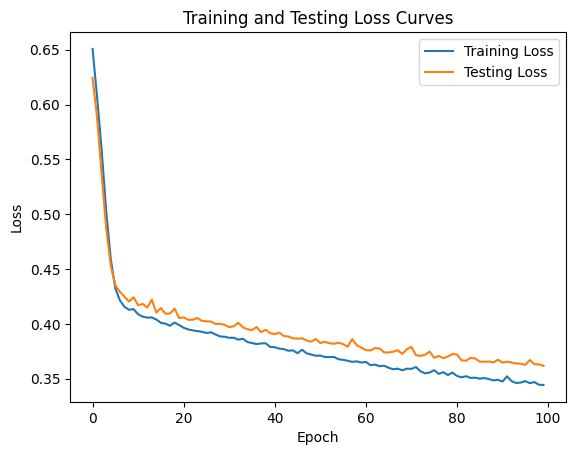

In [33]:
# Plot the training and testing loss curves
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Testing Loss')
plt.title('Training and Testing Loss Curves')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Step 6: Evaluate the model

In [34]:
pred_probability = model.predict(x_test)
pred_probability

227/227 [==============================] - 0s 933us/step


array([[0.85548455],
       [0.3097043 ],
       [0.02220158],
       ...,
       [0.32163036],
       [0.7039513 ],
       [0.06528928]], dtype=float32)

In [35]:
# Results with new threshold

custom_threshold = 0.5

# Apply the custom threshold to obtain binary predictions
custom_predictions = (pred_probability > custom_threshold).astype(int)
print(pred_probability )
print(custom_predictions)

[[0.85548455]
 [0.3097043 ]
 [0.02220158]
 ...
 [0.32163036]
 [0.7039513 ]
 [0.06528928]]
[[1]
 [0]
 [0]
 ...
 [0]
 [1]
 [0]]


In [36]:

conf_matrix = confusion_matrix(y_test, custom_predictions)
acc_score = accuracy_score(y_test, custom_predictions)
print("confussion matrix")
print(conf_matrix)
print("\n")
print("Accuracy of NN:",acc_score*100,'\n')
print(classification_report(y_test,custom_predictions))

confussion matrix
[[4308  546]
 [ 637 1764]]


Accuracy of NN: 83.69400413507925 

              precision    recall  f1-score   support

           0       0.87      0.89      0.88      4854
           1       0.76      0.73      0.75      2401

    accuracy                           0.84      7255
   macro avg       0.82      0.81      0.81      7255
weighted avg       0.84      0.84      0.84      7255



# Step 7: Precison Recall analysis

In [37]:
precision, recall, thresholds = precision_recall_curve(y_test, pred_probability)

In [38]:
#Precision = TP / (TP + FP)
#Precision indicates the proportion of positive predictions that were actually correct.

# for something like cancer prediciton -
# not cancer - class 0
# cancer - class 1
# default threshold: 0.5 
# 0.4 - cancer - increase the chance of catching cancer cases - increae chance of false postives

#Recall = TP / (TP + FN)
#Recall indicates the proportion of actual positive instances that were correctly identified by the model.

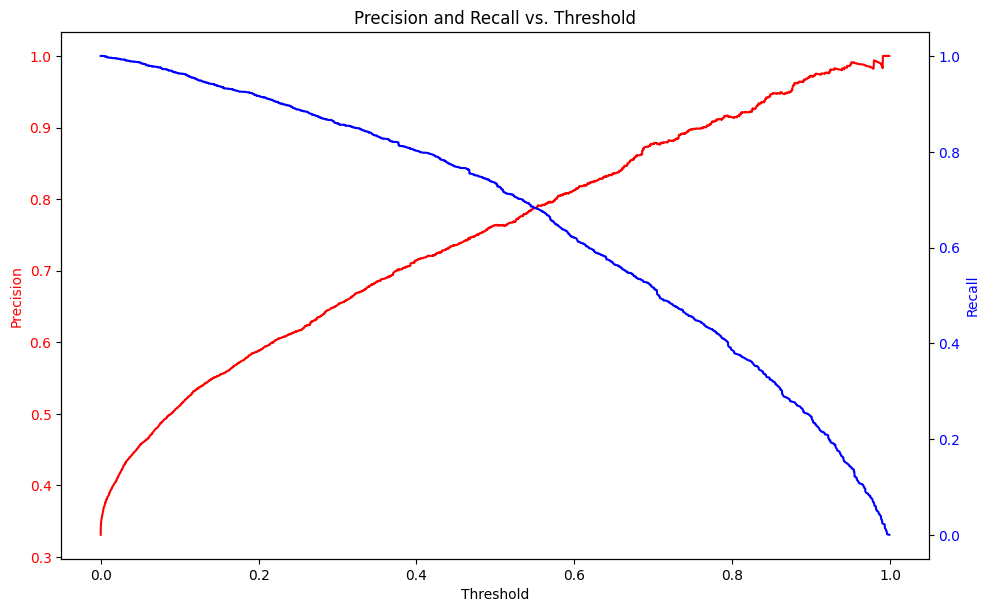

In [39]:
import numpy as np
# Plot precision and recall on separate y-axes
fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.set_xlabel('Threshold')
ax1.set_ylabel('Precision', color='red')
ax1.plot(thresholds, precision[:-1], color='red', label='Precision')
ax1.tick_params(axis='y', labelcolor='red')

ax2 = ax1.twinx()
ax2.set_ylabel('Recall', color='blue')
ax2.plot(thresholds, recall[:-1], color='blue', label='Recall')
ax2.tick_params(axis='y', labelcolor='blue')


fig.tight_layout()
plt.title('Precision and Recall vs. Threshold')
plt.show()


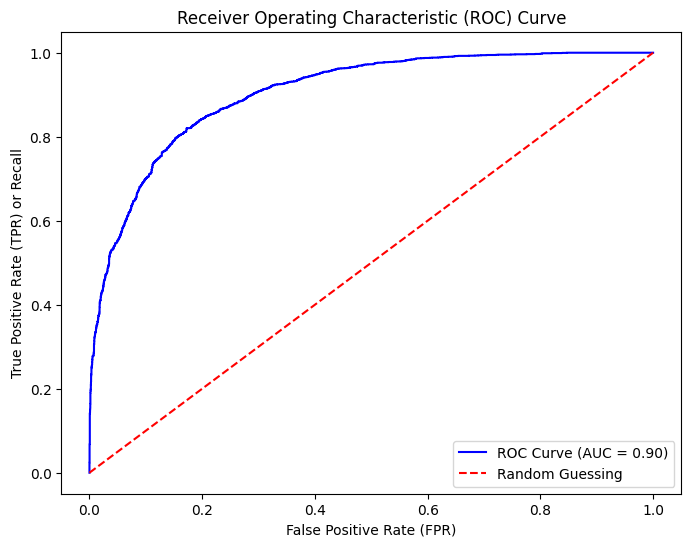

In [40]:
# applicable for any binary classfication model 

#FPR = FP / (FP + TN)
#It measures the proportion of actual negative instances that are incorrectly predicted as positive.

#TPR = TP / (TP + FN)
#It measures the proportion of actual positive instances that are correctly predicted as positive.

from sklearn.metrics import roc_curve, auc


# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, pred_probability)

# Calculate AUC
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', label=f'ROC Curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='red', linestyle='--', label='Random Guessing')

plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR) or Recall')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.show()